# Bài toán 3 — Thảo luận, demo và báo cáo

## 9. Giải thích và thảo luận

### 9.1. Mục tiêu và phạm vi thực nghiệm

Dự báo Revenue (doanh thu theo định nghĩa nguồn) và COGS (giá vốn hàng bán) theo ngày, với kỳ dự báo **548 ngày**. Toàn bộ lịch sử gồm 3.833 ngày; tập phát triển gồm 3.285 ngày từ **04/07/2012 đến 01/07/2021**, tập đánh giá cuối từ **02/07/2021 đến 31/12/2022**. Ba lượt validation theo thời gian, mỗi lượt 548 ngày, nằm trong tập phát triển. Ở từng lượt, chỉ dùng dữ liệu trước ngày bắt đầu dự báo để huấn luyện; không sử dụng giao dịch tương lai hoặc nhãn test để tinh chỉnh tham số trong quy trình hiện tại.

Nguồn dữ liệu: `sales.csv`, `orders.csv`, `order_items.csv`, `products.csv`. Revenue và COGS được đối soát theo định nghĩa nguồn, lần lượt là tổng `quantity × unit_price` và `quantity × cogs`. Không trừ giảm giá thêm lần nữa. Dữ liệu danh mục sản phẩm được xem là dữ liệu tham chiếu tĩnh, do nguồn không cung cấp lịch sử phiên bản.

**Thứ tự thực hiện:** 01 — khám phá dữ liệu → 02 — xây dựng mô hình → 03 — đánh giá → 04 — phân tích sai số và độ nhạy → 05 — thảo luận và demo. Notebook này đọc lại dự báo của notebook 02; không huấn luyện lại mô hình, không sửa dữ liệu và không xuất thêm tệp.

### 9.2. Từ mô hình cơ bản đến mô hình đề xuất

| Giai đoạn | Cách tiếp cận | Cơ sở chuyển tiếp |
|---|---|---|
| Đối chứng cơ bản | Naive, trung bình 28 ngày, theo thứ, ETS, ARIMA | Đánh giá khả năng dự báo bằng mức và động học đơn giản |
| Xu hướng và mùa vụ | Hồi quy tuyến tính, hồi quy + mùa vụ, baseline cuộc thi | Khai thác xu hướng và mẫu lịch dài hạn |
| Mùa vụ cải tiến | Mức gốc cố định; mức gốc cố định + hiệu ứng thứ | Mẫu theo tháng–ngày và thứ trong tuần; tránh ngoại suy xu hướng không phù hợp |
| Mô hình chính | Hybrid Ensemble phân rã và phân khúc | Mức kinh doanh thay đổi, các thành phần doanh thu biến động khác nhau, có quy luật chẵn/lẻ và khác biệt giữa phân khúc |

Tổng cộng 11 phương pháp được so sánh ở notebook 02–03. Các bước bên trong Hybrid là thành phần của **một mô hình**, không phải các mô hình đối chứng riêng.

Mô hình mùa vụ có hiệu ứng thứ dự báo theo mức trung bình ngày của năm đầy đủ gần nhất, nhân với hệ số mùa vụ tháng–ngày và hệ số thứ trong tuần, được học riêng cho Revenue và COGS. Mức gốc cố định trong kỳ dự báo làm mô hình khó thích nghi nếu mức kinh doanh thay đổi.

Từ notebook 01, Revenue và COGS trung bình ngày năm 2019 giảm lần lượt 38,6% và 34,8% so với 2018; số dòng hàng/ngày giảm 40,21% trong khi Revenue/dòng tăng 2,76% và COGS/dòng tăng 9,01%. Tỷ lệ giá bán/giá tham chiếu năm chẵn và năm lẻ lần lượt khoảng 94,69% và 90,74% (2013–2020). Giá trị trung bình mỗi dòng còn khác biệt giữa tám phân khúc. Đây là bằng chứng mô tả để đề xuất kiến trúc, chưa phải bằng chứng cải thiện dự báo hay quan hệ nhân quả.

### 9.3. Kiến trúc Hybrid Ensemble phân rã và phân khúc

Với ngày $t$, nếu $N_t$ là số dòng hàng và $\bar r_t,\bar c_t$ là giá trị trung bình trên mỗi dòng thì:

$$Revenue_t=N_t\bar r_t,\qquad COGS_t=N_t\bar c_t.$$

Nhánh phân khúc dự báo riêng các thành phần cho mỗi nhóm $s$ rồi tổng hợp:

$$\widehat{Revenue}_t=\sum_{s=1}^{8}\widehat N_{s,t}\widehat{\bar r}_{s,t},\qquad \widehat{COGS}_t=\sum_{s=1}^{8}\widehat N_{s,t}\widehat{\bar c}_{s,t}.$$

| Thành phần | Vai trò trong kiến trúc |
|---|---|
| Poisson Regression + HistGradient Boosting (65%–35%) | Dự báo số dòng hàng, kết hợp mô hình đếm và quan hệ phi tuyến |
| Ridge Regression | Học xu hướng giá tham chiếu, giá vốn và các thành phần mức kinh doanh |
| Mùa vụ lịch sử + CatBoost | Học hình dạng biến động theo ngày; phối hợp dự báo thành phần, mẫu mùa vụ và CatBoost theo tỷ lệ 65%–20%–15% |
| Recovery Gate | Điều chỉnh phục hồi có điều kiện dựa trên lịch sử suy giảm và tín hiệu tăng trưởng |
| Hiệu chỉnh ngoài mẫu | Học sai lệch theo lịch từ những lượt validation đã kết thúc; bỏ qua nếu chưa có dữ liệu |
| Xu hướng giảm dần và Ridge + Fourier | Bổ sung xu hướng thành phần, đặc trưng chẵn/lẻ; nhánh chu kỳ hai năm phối hợp 15% trên log tỷ lệ |
| Nhánh tám phân khúc | Dự báo số dòng, Revenue/dòng và COGS/dòng theo từng nhóm; phối hợp 30% trên log tỷ lệ sau chuẩn hóa mức theo năm hoặc phần năm dự báo |

Luồng xử lý: **giao dịch lịch sử → dự báo thành phần → ensemble mùa vụ/CatBoost → phục hồi có điều kiện → hiệu chỉnh ngoài mẫu và xu hướng → chu kỳ hai năm → dự báo theo phân khúc → Revenue, COGS theo ngày**.

Các đặc trưng lịch của kỳ dự báo có thể biết trước; các hệ số được học tại từng mốc huấn luyện. Tổng hợp tháng/năm chỉ sử dụng kỳ đã hoàn tất. Chi tiết công thức và tham số nằm trong notebook 02.

### 9.4. Đọc dự báo và đối chiếu kết quả

Tính lại chỉ số từ tệp dự báo đã lưu, không huấn luyện hoặc chọn lại mô hình theo test. MAE và RMSE tính theo triệu đơn vị tiền tệ/ngày; R² không có đơn vị. Bảng đầy đủ 11 mô hình trên test nằm ở notebook 03; notebook này tập trung vào các đối chứng chính và Hybrid.

In [1]:
from pathlib import Path
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

sales_path = Path("data/raw/sales.csv")
start = Path(os.environ.get("RETAIL_ANALYTICS_ROOT", Path.cwd())).resolve()
project_root = next(
    (folder for folder in (start, *start.parents) if (folder / sales_path).is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "Không tìm thấy data/raw/sales.csv. Hãy đặt notebook trong dự án "
        "hoặc trỏ RETAIL_ANALYTICS_ROOT về thư mục gốc."
    )

prediction_path = project_root / "data/model/du_bao/forecast_predictions.csv"
if not prediction_path.is_file():
    raise FileNotFoundError("Chạy 02_mo_hinh.ipynb để tạo forecast_predictions.csv.")

predictions = pd.read_csv(
    prediction_path, parse_dates=["Date", "TrainEnd"], float_precision="round_trip",
)
targets = ["Revenue", "COGS"]

observed = pd.read_csv(
    project_root / sales_path, usecols=["Date", *targets], parse_dates=["Date"],
).set_index("Date").sort_index()[targets]
if not observed.index.is_unique:
    raise ValueError("sales.csv có ngày trùng. Kiểm tra lại ở 01_du_lieu.ipynb.")

contest_name = "Baseline cuộc thi"
fixed_name = "Mùa vụ, mức gốc cố định"


def prediction_frame(rows):
    return rows.set_index("Date")[targets].sort_index()


def test_forecast_for(method):
    return prediction_frame(predictions.loc[
        predictions["Split"].eq("test") & predictions["Method"].eq(method)
    ])


def evaluate(actual, forecast):
    pd.testing.assert_index_equal(actual.index, forecast.index)
    pd.testing.assert_index_equal(actual.columns, forecast.columns)
    if not np.isfinite(forecast.to_numpy(dtype=float)).all():
        raise ValueError("Dự báo có giá trị thiếu hoặc không hữu hạn.")
    actual = actual.astype(float) / 1_000_000
    error = forecast.astype(float) / 1_000_000 - actual
    squared_error = error.pow(2)
    variation = (actual - actual.mean()).pow(2).sum()
    return pd.DataFrame({
        "MAE": error.abs().mean(),
        "RMSE": np.sqrt(squared_error.mean()),
        "R²": 1 - squared_error.sum() / variation.where(variation > 0),
    }).rename_axis("Chỉ tiêu")

weekday_name = "Mùa vụ mức gốc cố định + hiệu ứng thứ"
hybrid_name = "Hybrid Ensemble phân rã và phân khúc"
method_order = ["Naive", "Trung bình 28 ngày", "Theo thứ trong tuần", "ETS (A,N,N)",
                "ARIMA(1,1,1)", "Hồi quy tuyến tính", "Hồi quy tuyến tính + mùa vụ",
                contest_name, fixed_name, weekday_name, hybrid_name]
dev_end = pd.Timestamp("2021-07-01")
final_dates = pd.date_range("2021-07-02", "2022-12-31", name="Date")
assert len(final_dates) == 548
assert observed.index.equals(pd.date_range("2012-07-04", "2022-12-31", name="Date"))
assert np.isfinite(observed.to_numpy(dtype=float)).all()
required_cols = {"Split", "Fold", "TrainEnd", "Date", "Method", *targets}
assert required_cols.issubset(predictions.columns)
assert not predictions.duplicated(["Split", "Fold", "Method", "Date"]).any()
assert np.isfinite(predictions[targets].to_numpy(dtype=float)).all()
assert (predictions.Date > predictions.TrainEnd).all()
validation = predictions.loc[predictions.Split.eq("validation")].copy()
assert set(validation.Method) == set(method_order), "Cần chạy notebook 02 bản cập nhật đủ 11 mô hình."
fold_windows = {1:("2016-12-31","2018-07-01"), 2:("2018-07-02","2019-12-31"), 3:("2020-01-01","2021-07-01")}
assert set(validation.Fold) == set(fold_windows)
for fold_id, (lo, hi) in fold_windows.items():
    block = validation.loc[validation.Fold.eq(fold_id)]
    assert set(block.Method) == set(method_order)
    for method, rows in block.groupby("Method"):
        assert prediction_frame(rows).index.equals(pd.date_range(lo, hi, name="Date"))
        assert rows.TrainEnd.eq(pd.Timestamp(lo) - pd.Timedelta(days=1)).all()
test_rows = predictions.loc[predictions.Split.eq("test")]
assert test_rows.TrainEnd.eq(dev_end).all() and test_rows.Fold.eq(0).all()
assert {contest_name, fixed_name, weekday_name, hybrid_name}.issubset(test_rows.Method.unique())
for method, rows in test_rows.groupby("Method"):
    assert prediction_frame(rows).index.equals(final_dates)
print(f"Đã kiểm tra {len(validation):,} dòng validation và {len(test_rows):,} dòng test từ notebook 02.")

Đã kiểm tra 18,084 dòng validation và 2,740 dòng test từ notebook 02.


In [2]:
# Kết quả validation: tính từng lượt rồi lấy trung bình.
rows = []
for (fold_id, method), block in validation.groupby(["Fold", "Method"], sort=False):
    pred = prediction_frame(block)
    rows.append(evaluate(observed.loc[pred.index], pred).assign(Fold=fold_id, Method=method))
val_scores = pd.concat(rows).reset_index()
val_summary = val_scores.groupby(["Method", "Chỉ tiêu"])[["MAE", "RMSE", "R²"]].mean()
val_mae = val_summary["MAE"].unstack("Chỉ tiêu").reindex(index=method_order, columns=targets)
validation_best = val_mae.idxmin()
print("MAE trung bình 3 lượt validation (triệu/ngày):")
display(val_mae.round(6))
print("Kết quả đứng đầu validation theo MAE")
display(validation_best.rename("Phương pháp"))
print("MAE theo lượt của hai phương pháp trọng tâm:")
display(val_scores.loc[val_scores.Method.isin([weekday_name, hybrid_name])].pivot(index="Fold", columns=["Method", "Chỉ tiêu"], values="MAE").round(6))

# Kết quả test của Hybrid và ba phương pháp đối chứng.
methods = [contest_name, fixed_name, weekday_name, hybrid_name]
test_actual = observed.loc[final_dates, targets]
main_forecasts = {name:test_forecast_for(name) for name in methods}
validation_reference = pd.DataFrame({
    target: test_forecast_for(validation_best[target])[target] for target in targets
}, index=final_dates)
metrics = pd.concat({name:evaluate(test_actual, pred) for name,pred in main_forecasts.items()}, names=["Phương pháp"])
print("Chỉ số test trên 548 ngày:")
display(metrics.round(6))
aggregate = metrics.groupby(level="Phương pháp")["MAE"].mean().sort_values()
display(aggregate.rename("MAE tổng hợp (triệu/ngày)").round(6))

ref = evaluate(test_actual, validation_reference)
new = evaluate(test_actual, main_forecasts[hybrid_name])
base = evaluate(test_actual, main_forecasts[contest_name])
comparison = new.copy()
comparison["Giảm MAE so với đối chứng validation (%)"] = 100*(1-new.MAE/ref.MAE)
comparison["Giảm RMSE so với đối chứng validation (%)"] = 100*(1-new.RMSE/ref.RMSE)
comparison["Giảm MAE so với baseline (%)"] = 100*(1-new.MAE/base.MAE)
print("Kết quả Hybrid và mức cải thiện:")
display(comparison.round(6))

MAE trung bình 3 lượt validation (triệu/ngày):


Chỉ tiêu,Revenue,COGS
Method,,
Naive,3.123752,3.039196
Trung bình 28 ngày,3.091022,2.504237
Theo thứ trong tuần,3.105716,2.524641
"ETS (A,N,N)",3.125365,3.040859
"ARIMA(1,1,1)",3.171440,2.604919
Hồi quy tuyến tính,2.459694,2.137894
Hồi quy tuyến tính + mùa vụ,1.857832,1.617387
Baseline cuộc thi,1.375094,1.194796
"Mùa vụ, mức gốc cố định",1.211976,1.048035


Kết quả đứng đầu validation theo MAE


Chỉ tiêu
Revenue    Mùa vụ mức gốc cố định + hiệu ứng thứ
COGS       Mùa vụ mức gốc cố định + hiệu ứng thứ
Name: Phương pháp, dtype: object

MAE theo lượt của hai phương pháp trọng tâm:


Method   Mùa vụ mức gốc cố định + hiệu ứng thứ            \
Chỉ tiêu                               Revenue      COGS   
Fold                                                       
1                                     1.104845  0.904133   
2                                     1.791294  1.597619   
3                                     0.649164  0.553106   

Method   Hybrid Ensemble phân rã và phân khúc            
Chỉ tiêu                              Revenue      COGS  
Fold                                                     
1                                    0.912259  0.796726  
2                                    2.457179  2.148548  
3                                    0.526077  0.449195

Chỉ số test trên 548 ngày:


MAE      RMSE        R²
Phương pháp                           Chỉ tiêu                              
Baseline cuộc thi                     Revenue   0.690395  0.959012  0.618675
                                      COGS      0.678900  0.923072  0.544235
Mùa vụ, mức gốc cố định               Revenue   0.595752  0.820935  0.720575
                                      COGS      0.541723  0.752410  0.697184
Mùa vụ mức gốc cố định + hiệu ứng thứ Revenue   0.576955  0.797846  0.736072
                                      COGS      0.526686  0.733653  0.712094
Hybrid Ensemble phân rã và phân khúc  Revenue   0.498090  0.692987  0.800888
                                      COGS      0.439392  0.604945  0.804250

Phương pháp
Hybrid Ensemble phân rã và phân khúc     0.468741
Mùa vụ mức gốc cố định + hiệu ứng thứ    0.551821
Mùa vụ, mức gốc cố định                  0.568737
Baseline cuộc thi                        0.684648
Name: MAE tổng hợp (triệu/ngày), dtype: float64

Kết quả Hybrid và mức cải thiện:


,MAE,RMSE,R²,Giảm MAE so với đối chứng validation (%),Giảm RMSE so với đối chứng validation (%),Giảm MAE so với baseline (%)
Chỉ tiêu,,,,,,
Revenue,0.498090,0.692987,0.800888,13.669246,13.142857,27.854359
COGS,0.439392,0.604945,0.804250,16.574235,17.543462,35.278895


### 9.5. Thảo luận kết quả và giới hạn

Trên ba lượt validation, mùa vụ mức gốc cố định có hiệu ứng thứ có MAE trung bình thấp nhất cho Revenue và COGS, lần lượt là 1,181767 và 1,018286 triệu/ngày. Hybrid đạt 1,298505 và 1,131490 triệu/ngày. So với mùa vụ có hiệu ứng thứ, Hybrid có sai số thấp hơn ở lượt 1 và 3, cao hơn ở lượt 2. Lượt 2 bao gồm giai đoạn suy giảm mạnh năm 2019; đây là một bối cảnh có thể giải thích sai số lớn, không phải chứng minh nguyên nhân cụ thể.

Hybrid Ensemble là mô hình dự báo chính của bài toán này. Trên 548 ngày test hồi cứu, Hybrid đạt MAE thấp nhất, RMSE thấp nhất và R² cao nhất trong 11 phương pháp đã thực nghiệm (notebook 03). Thứ hạng thay đổi giữa validation và test cho thấy hiệu quả dự báo phụ thuộc giai đoạn đánh giá.

**Thực nghiệm loại bỏ thành phần** (trích kết quả đã chạy và lưu tại mục 8.3 notebook 04, không tính lại ở đây):

| Cấu hình bị loại | Δ MAE tổng hợp validation (triệu) | Δ MAE tổng hợp test (triệu) |
|---|---:|---:|
| CatBoost | +0,002874 | +0,001881 |
| Recovery Gate | 0,000000 | 0,000000 |
| Hiệu chỉnh ngoài mẫu | −0,000500 | +0,000686 |
| Xu hướng giảm dần | +0,003031 | +0,000900 |
| Chu kỳ hai năm | −0,000565 | +0,000562 |
| Nhánh phân khúc | +0,001526 | +0,002251 |

Δ MAE = MAE khi bỏ thành phần − MAE Hybrid đầy đủ; giá trị dương nghĩa là việc loại bỏ làm tăng sai số. Nhánh phân khúc có chênh lệch lớn nhất trên test trong sáu phép loại bỏ; CatBoost và xu hướng giảm dần cũng có đóng góp tích cực trên validation và test. Recovery Gate không làm thay đổi kết quả tại các mốc khảo sát. Hiệu chỉnh ngoài mẫu và chu kỳ hai năm không cải thiện MAE trung bình validation, dù có lợi trên test. Các chênh lệch phụ thuộc kiến trúc, không được cộng lại thành tổng đóng góp.

Kiến trúc đã từng được khảo sát hồi cứu với lịch sử rộng hơn, nên tập test này không hoàn toàn độc lập đối với quá trình hình thành kiến trúc. Việc cắt thời gian và huấn luyện lại theo từng mốc trong bài thực nghiệm hiện tại không loại bỏ được giới hạn đó.

In [3]:
# Kiểm tra ngày có sai số tuyệt đối lớn nhất của Hybrid.
hybrid_test_forecast = main_forecasts[hybrid_name]
for target in targets:
    actual = test_actual[target]/1e6
    pred = hybrid_test_forecast[target]/1e6
    errors = pd.DataFrame({"Thực tế":actual, "Dự báo":pred, "Sai số có dấu":pred-actual, "Sai số tuyệt đối":(pred-actual).abs()})
    print(target, "— 5 ngày có sai số tuyệt đối lớn nhất (triệu đơn vị tiền tệ)")
    display(errors.nlargest(5, "Sai số tuyệt đối").round(3))

Revenue — 5 ngày có sai số tuyệt đối lớn nhất (triệu đơn vị tiền tệ)


,Thực tế,Dự báo,Sai số có dấu,Sai số tuyệt đối
Date,,,,
2022-03-02,5.222,1.891,-3.331,3.331
2022-08-01,4.082,7.008,2.926,2.926
2022-02-28,6.007,3.574,-2.433,2.433
2022-05-20,2.227,4.625,2.399,2.399
2022-02-26,6.305,3.950,-2.355,2.355


COGS — 5 ngày có sai số tuyệt đối lớn nhất (triệu đơn vị tiền tệ)


,Thực tế,Dự báo,Sai số có dấu,Sai số tuyệt đối
Date,,,,
2022-03-02,4.446,1.538,-2.909,2.909
2021-09-02,4.722,2.155,-2.567,2.567
2022-08-01,3.201,5.522,2.321,2.321
2021-08-28,2.453,4.609,2.156,2.156
2022-02-28,4.943,2.894,-2.049,2.049


Ngày 02/03/2022 có sai số tuyệt đối lớn nhất đối với cả hai chỉ tiêu của Hybrid (dự báo thấp hơn thực tế khoảng 3,331 triệu Revenue và 2,909 triệu COGS). Mô hình vẫn có thể bỏ lỡ biến động đột biến theo ngày. Không thể quy kết sai số này cho một chương trình khuyến mãi hay sự kiện cụ thể khi chưa có bằng chứng bổ sung.

## 10. Demo dự báo trong notebook

Đổi `demo_start` và `demo_end` để chọn một khoảng trong 548 ngày test. Demo mặc định dùng Hybrid và hiển thị giá trị thực tế cùng dự báo đối chứng đứng đầu validation. Đổi `demo_method` để minh họa một phương pháp khác đã có dự báo.

Notebook 03 xuất dự báo Hybrid vào `data/model/du_bao/forecast_2021-07-01.csv`, đường dẫn dùng cho Streamlit, và `forecast_hybrid_2021-07-01.csv` trong cùng thư mục.

Thực tế             MAE validation thấp nhất              \
               Revenue        COGS                  Revenue        COGS   
Date                                                                      
2021-07-02  4397949.68  4326458.07               4209737.42  4026908.63   
2021-07-03  3132513.38  3101143.37               3725039.19  3573674.29   
2021-07-04   730601.15   647312.84               1240758.54  1091703.73   
2021-07-05  1878817.85  1927429.12               1610694.44  1485779.33   
2021-07-06  1616214.16  1626948.22               1787767.69  1673779.67   
2021-07-07  1741509.60  1715092.93               2186756.77  2068807.26   
2021-07-08  2563149.38  2518109.42               1977447.94  1889918.16   

                Hybrid              
               Revenue        COGS  
Date                                
2021-07-02  5175120.35  5075407.97  
2021-07-03  3959283.60  3979042.62  
2021-07-04  1192397.78  1150932.86  
2021-07-05  1610320.21  1585438.23  
2021-07-06  1801257.31  1777827.74  
2021-07-07  2333472.09  2316986.94  
2021-07-08  2565205.99  2544024.71

Mô hình đang minh họa: Hybrid Ensemble phân rã và phân khúc


,MAE,RMSE,R²
Chỉ tiêu,,,
Revenue,0.444757,0.528820,0.771937
COGS,0.464450,0.546147,0.753000


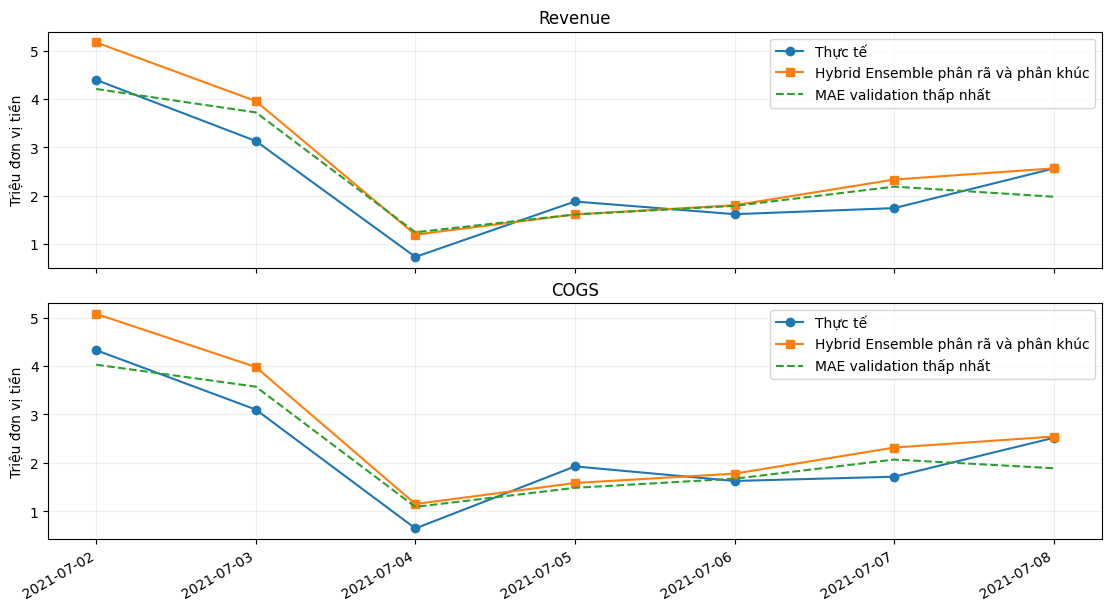

In [4]:
demo_start = "2021-07-02"
demo_end = "2021-07-08"
demo_method = hybrid_name  # Hoặc weekday_name, contest_name, fixed_name.
lo, hi = pd.Timestamp(demo_start), pd.Timestamp(demo_end)
if not (final_dates.min() <= lo <= hi <= final_dates.max()):
    raise ValueError("Khoảng demo phải nằm trong 02/07/2021–31/12/2022.")
if demo_method not in main_forecasts:
    raise ValueError("Chọn một phương pháp trong danh sách methods.")
demo_dates = pd.date_range(lo, hi, name="Date")
demo = pd.concat({"Thực tế":test_actual.loc[demo_dates], "MAE validation thấp nhất":validation_reference.loc[demo_dates], "Hybrid":hybrid_test_forecast.loc[demo_dates]}, axis=1)
display(demo.round(2))
print(f"Mô hình đang minh họa: {demo_method}")
display(evaluate(test_actual.loc[demo_dates],main_forecasts[demo_method].loc[demo_dates]).round(6))
fig, axes = plt.subplots(2, 1, figsize=(11,6), sharex=True, layout="constrained")
for ax, target in zip(axes, targets):
    ax.plot(demo_dates, test_actual.loc[demo_dates,target]/1e6, marker="o", label="Thực tế")
    ax.plot(demo_dates, main_forecasts[demo_method].loc[demo_dates,target]/1e6, marker="s", label=demo_method)
    if demo_method != validation_best[target]:
        ax.plot(demo_dates,validation_reference.loc[demo_dates,target]/1e6, linestyle="--", label="MAE validation thấp nhất")
    ax.set_title(target); ax.set_ylabel("Triệu đơn vị tiền"); ax.legend(); ax.grid(alpha=.2)
fig.autofmt_xdate(); plt.show()

## 11. Nội dung đưa vào báo cáo

### 11.1. Tóm tắt phương pháp và kết quả

Nhóm nghiên cứu dự báo Revenue và COGS trong 548 ngày liên tiếp bằng dữ liệu bán hàng theo ngày và dữ liệu giao dịch. Dữ liệu từ 04/07/2012 đến 01/07/2021 được dùng để phát triển mô hình và thực hiện ba lượt validation theo thời gian; dữ liệu từ 02/07/2021 đến 31/12/2022 được dùng để đánh giá hồi cứu. Các phương pháp cơ bản, mô hình xu hướng, mùa vụ và baseline được giữ làm đối chứng. Từ sự thay đổi mức kinh doanh, biến động khác nhau của số dòng hàng và giá trị mỗi dòng, chu kỳ năm chẵn/lẻ và khác biệt giữa phân khúc, nhóm xây dựng Hybrid Ensemble kết hợp phân rã doanh thu và phân khúc sản phẩm.

Nhóm dùng Hybrid Ensemble làm mô hình dự báo chính cho Revenue và COGS. Mùa vụ mức gốc cố định có hiệu ứng thứ đứng đầu theo MAE trung bình validation ở cả hai chỉ tiêu. Hybrid đạt MAE, RMSE và R² tốt nhất trong kỳ test hồi cứu của 11 phương pháp.

| Chỉ tiêu | MAE (triệu/ngày) | RMSE (triệu/ngày) | R² | Giảm MAE so với mùa vụ có hiệu ứng thứ |
|---|---:|---:|---:|---:|
| Revenue | 0,498090 | 0,692987 | 0,800888 | 13,67% |
| COGS | 0,439392 | 0,604945 | 0,804250 | 16,57% |

MAE trung bình cộng của hai mục tiêu khoảng 0,468741 triệu/ngày (đối chứng 0,551821 triệu/ngày). Thực nghiệm loại bỏ thành phần cho thấy nhánh phân khúc, CatBoost và xu hướng giảm dần có đóng góp tích cực trong các phép so sánh; các thành phần khác không đồng nhất giữa các giai đoạn, và Recovery Gate không làm thay đổi kết quả tại các mốc kiểm định. Kết quả cho thấy tiềm năng của kiến trúc Hybrid trong giai đoạn đánh giá, nhưng không đủ để khẳng định ưu thế chung cho mọi giai đoạn do khác biệt giữa validation và test và giới hạn về tính độc lập của tập đánh giá.

### 11.2. Ý nghĩa nghiệp vụ

- **Lập kế hoạch doanh thu:** dùng dự báo theo ngày/tháng để tham khảo mục tiêu bán hàng; xem xét sai số lịch sử trước khi quyết định.
- **Lập kế hoạch giá vốn:** kết hợp dự báo Revenue và COGS để tham khảo chi phí và chênh lệch doanh thu–giá vốn; không xem chênh lệch này là lợi nhuận ròng.
- **Theo dõi biến động:** nhận diện giai đoạn dự báo thấp/cao bất thường, đặc biệt những ngày có sai số lớn. Cần kết hợp dữ liệu nghiệp vụ trước khi quy kết nguyên nhân.
- **Quản trị mô hình:** theo dõi MAE/RMSE theo kỳ khi có dữ liệu mới; so sánh với mô hình mùa vụ đơn giản và đánh giá lại khi mức kinh doanh hoặc cơ cấu sản phẩm thay đổi.

Các ứng dụng này là đề xuất nghiệp vụ, chưa được kiểm chứng về hiệu quả triển khai thực tế. Mô hình dự báo tổng Revenue và COGS, không trực tiếp dự báo tồn kho từng SKU.

### 11.3. Hạn chế và hướng phát triển

Giá và giá vốn tham chiếu không có lịch sử phiên bản; mô hình chưa giải thích đầy đủ các cú sốc bất thường. Kiến trúc phức tạp hơn có chi phí tính toán và bảo trì cao hơn phương pháp mùa vụ. Tập đánh giá hồi cứu không độc lập hoàn toàn với quá trình nghiên cứu kiến trúc; không điều chỉnh lại mô hình bằng nhãn test. Hướng phát triển là kiểm định trên một giai đoạn tương lai độc lập, cập nhật đặc trưng nghiệp vụ có thể biết trước, nghiên cứu khoảng dự báo và đánh giá chi phí vận hành.

## 12. Thuyết trình và vấn đáp

**Mạch trình bày:** mục tiêu và dữ liệu → phát hiện EDA → các mô hình đối chứng → hạn chế của mùa vụ mức gốc cố định → phân rã và Hybrid Ensemble → so sánh validation/test → ablation và sai số → demo, ý nghĩa nghiệp vụ, hạn chế.

| Câu hỏi có thể gặp | Cách giải thích |
|---|---|
| Vì sao không chia dữ liệu ngẫu nhiên? | Dự báo chuỗi thời gian chỉ được dùng lịch sử đến mốc dự báo. Chia theo thời gian mô phỏng đúng điều kiện này. |
| Vì sao cần các mô hình mùa vụ cơ bản? | Chúng là đối chứng dễ giải thích; giúp đánh giá giá trị gia tăng của kiến trúc phức tạp và khai thác mẫu lịch đã quan sát. |
| Vì sao phát triển Hybrid? | Mức kinh doanh thay đổi, số dòng hàng và giá trị mỗi dòng biến động khác nhau, chu kỳ chẵn/lẻ và khác biệt phân khúc tạo cơ sở để dự báo thành phần và phối hợp nhiều phương pháp. |
| Vì sao dùng Poisson và HistGradient Boosting? | Poisson phù hợp với dữ liệu đếm; HistGradient Boosting bổ sung quan hệ phi tuyến. Ridge có điều chuẩn cho xu hướng/giá trị, CatBoost học hình dạng biến động theo ngày. |
| Mô hình nào được dùng để dự báo? | Hybrid Ensemble là mô hình chính cho Revenue và COGS. Mùa vụ có hiệu ứng thứ đứng đầu theo MAE validation. Hybrid đứng đầu theo MAE, RMSE và R² trên test hồi cứu. |
| MAE, RMSE và R² có ý nghĩa gì? | MAE đo sai số tuyệt đối trung bình; RMSE nhấn mạnh sai số lớn; R² so với mức tham chiếu trung bình thực tế, có thể âm. |
| Thành phần nào có đóng góp lớn nhất? | Trong sáu phép loại bỏ trên test, nhánh phân khúc có chênh lệch MAE tổng hợp lớn nhất. Không cộng các chênh lệch để suy ra tổng đóng góp. |
| Recovery Gate có cải thiện không? | Không làm thay đổi dự báo tại các mốc thực nghiệm hiện tại; không được tuyên bố là nguyên nhân giảm sai số. |
| Làm sao hạn chế rò rỉ dữ liệu? | Cắt dữ liệu theo từng mốc, chỉ dùng kỳ tháng/năm đầy đủ và sai số ngoài mẫu đã có nhãn trước mốc dự báo. Tuy nhiên, tập test không hoàn toàn độc lập với quá trình nghiên cứu kiến trúc trước đó. |
| Hạn chế chính của Hybrid? | Không thắng trung bình validation, có thể sai lớn khi có đột biến, phụ thuộc dữ liệu giao dịch và giả định giá tham chiếu, phức tạp hơn đối chứng. |

**Kết luận:** Bài toán 3 hoàn thành quy trình khám phá dữ liệu, xây dựng 11 phương pháp, đánh giá theo thời gian, phân tích độ nhạy và demo. Hybrid Ensemble là mô hình dự báo chính trong demo và tệp dành cho ứng dụng. Mùa vụ có hiệu ứng thứ là đối chứng đứng đầu validation. Kết quả test mô tả kỳ đánh giá hồi cứu 548 ngày.